# Практична робота №2
## Логістична регресія та федеративне навчання

Студент: Панчишин Володимир

**Мета:** Реалізувати багатокласову логістичну регресію та FedAvg; порівняти центральні, локальні й глобальні моделі за різних розподілів даних.

Джерело завдання: https://github.com/olehsinkevych/machine-learning

**Відтворення:** середовище Python 3.12, залежності в requirements.txt; перед запуском усієї роботи завантажте дані командою `python download_data.py`. Усі результати нижче отримуються виконанням коду, а не копіюванням готових таблиць.

In [1]:
from pathlib import Path
import sys, os
for name in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ.setdefault(name, '2')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'project' / 'common.py').is_file())
sys.path.insert(0, str(ROOT / 'project'))
import common
from IPython.display import display, Image
import pandas as pd
import json

## 1. Теоретичні пояснення та відповіді на питання

### Softmax і крос-ентропія
Softmax перетворює логіти семи класів на додатні ймовірності із сумою 1. Віднімання максимуму рядка зберігає результат та запобігає переповненню exp. Cross-entropy відповідає від’ємному логарифму правдоподібності категоріальних міток.

### Градієнти і регуляризація
Для L = CE + λ||W||²/2 маємо dW = Xᵀ(P-Y)/m + λW та db = mean(P-Y). L2 плавно стискає ваги; L1 із субградієнтом sign(W) сприяє розрідженості. Bias не регуляризую, оскільки він задає базовий рівень логітів, а не складність залежності від ознак.

### Ізоляція вибірок і масштабування
Global Test становить 20%, Global Validation - 15%, решта 65% утворює FL Train Pool. Статистики масштабування не містять Validation або Test. Клієнти передають кількість прикладів, суми та суми квадратів; сервер обчислює спільні середні й дисперсії. Це симуляція; криптографічний захист агрегованих статистик тут не реалізований.

### Як працює FedAvg
Кожен клієнт отримує однакові глобальні W і b, виконує локальні епохи та повертає лише параметри й кількість прикладів. Сервер зважує модель клієнта на n_k / Σn_j. Просте незважене середнє надало б малим клієнтам непропорційний вплив. Центральна базова модель є окремим контрольним експериментом, а не доступом FL-сервера до сирих даних.

### Non-IID і client drift
За IID частки класів у клієнтів приблизно однакові. Dirichlet з малим α створює неоднорідні розподіли. Локальні градієнти тоді орієнтуються на різні цілі; багато локальних епох посилює client drift. Глобальна модель може бути гіршою за центральну та за окрему локальну модель. Експерименти E=1,5,10 мають однакові 60 раундів, проте різний обсяг локальних обчислень.

### Оцінювання і приватність
Для дисбалансу поряд з accuracy використовую macro-F1 і balanced accuracy, які не дають найбільшому класу приховати помилки інших. Log-loss додатково оцінює впевненість. Сирі дані клієнтів не передаються серверу, але сам FedAvg не гарантує повної приватності: параметри можуть розкривати інформацію без secure aggregation чи differential privacy. Гіперпараметри обираю на Global Validation, Test використовую для заздалегідь заданих кінцевих порівнянь.

### Додаткові питання з лекції 2: odds і logit
Для скінченного z сигмоїда σ(z)=1/(1+exp(-z)) лежить строго між 0 та 1. Тоді p/(1-p)=exp(z), а log(p/(1-p))=z - це і є виведення логіт-зв’язку. При p→1 відношення шансів прямує до нескінченності; точне p=1 робить ділення на нуль невизначеним. У floating-point p може округлитися до 1, тому втрату обчислюю через стабільні логіти й log-sum-exp, а не прямим log(1-p).

## 2. Повна реалізація

Далі міститься власна реалізація обчислень цієї роботи. Код також винесено в окремий файл `project/lab02.py`.

In [2]:
"""Практична 2: NumPy softmax і симуляція FedAvg без передачі сирих даних серверу."""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import f_classif
from common import (
    DATA,
    folder,
    savefig,
    dump,
    classification,
    cm_plot,
    numerical_gradient,
)

In [3]:
class SoftmaxRegression:
    def __init__(self, d, c, ridge=0):
        self.w = np.zeros((d, c))
        self.b = np.zeros(c)
        self.ridge = ridge

    def predict_proba(self, x):
        z = x @ self.w + self.b
        z -= z.max(1, keepdims=True)
        p = np.exp(z)
        return p / p.sum(1, keepdims=True)

    def predict(self, x):
        return self.predict_proba(x).argmax(1)

    def loss_grad(self, x, y):
        z = x @ self.w + self.b
        z -= z.max(1, keepdims=True)
        lse = np.log(np.exp(z).sum(1))
        loss = np.mean(lse - z[np.arange(len(y)), y]) + 0.5 * self.ridge * np.sum(
            self.w**2
        )
        p = self.predict_proba(x)
        p[np.arange(len(y)), y] -= 1
        p /= len(y)
        return loss, x.T @ p + self.ridge * self.w, p.sum(0)

    def fit_epoch(self, x, y, lr, batch, rng):
        ids = rng.permutation(len(y))
        for start in range(0, len(y), batch):
            idx = ids[start : start + batch]
            _, gw, gb = self.loss_grad(x[idx], y[idx])
            self.w -= lr * gw
            self.b -= lr * gb

    def state(self):
        return self.w.copy(), self.b.copy()

    def load(self, state):
        self.w, self.b = (v.copy() for v in state)

In [4]:
class Client:
    def __init__(self, x, y, seed):
        self.x = x.copy()
        self.y = y.copy()
        self.rng = np.random.default_rng(seed)

    def statistics(self):
        return len(self.x), self.x.sum(0), (self.x**2).sum(0)

    def scale(self, mean, std):
        self.x = (self.x - mean) / std

    def update(self, state, epochs, lr, ridge):
        model = SoftmaxRegression(state[0].shape[0], state[0].shape[1], ridge)
        model.load(state)
        for _ in range(epochs):
            model.fit_epoch(self.x, self.y, lr, 64, self.rng)
        # Транспортний контракт: тільки n, W і b, жодних X або y.
        return len(self.y), model.state()

In [5]:
class Aggregator:
    def __init__(self, d, c, xv, yv, ridge):
        self.model = SoftmaxRegression(d, c, ridge)
        self.xv = xv
        self.yv = yv

    def round(self, clients, epochs, lr, ridge):
        states = [
            client.update(self.model.state(), epochs, lr, ridge) for client in clients
        ]
        total = sum(n for n, _ in states)
        state = tuple(
            sum(n / total * weights[j] for n, weights in states) for j in range(2)
        )
        self.model.load(state)
        return {
            "validation_loss": float(self.model.loss_grad(self.xv, self.yv)[0]),
            "validation_accuracy": float(
                np.mean(self.model.predict(self.xv) == self.yv)
            ),
        }

In [6]:
def partition(y, k, alpha, seed):
    rng = np.random.default_rng(seed)
    if alpha is None:
        groups = [[] for _ in range(k)]
        for c in np.unique(y):
            ids = rng.permutation(np.flatnonzero(y == c))
            for j, p in enumerate(np.array_split(ids, k)):
                groups[j].extend(p)
        groups = [np.array(g, dtype=int) for g in groups]
    else:
        for attempt in range(100):
            groups = [[] for _ in range(k)]
            for c in np.unique(y):
                ids = rng.permutation(np.flatnonzero(y == c))
                proportions = rng.dirichlet(np.full(k, alpha))
                cut = (np.cumsum(proportions)[:-1] * len(ids)).astype(int)
                for j, p in enumerate(np.split(ids, cut)):
                    groups[j].extend(p)
            if min(map(len, groups)) >= 20:
                break
        groups = [np.array(g, dtype=int) for g in groups]
    flat = np.concatenate(groups)
    assert len(flat) == len(y) and len(np.unique(flat)) == len(y)
    return groups

In [7]:
def central(x, y, xv, yv, lr, ridge, epochs=150):
    m = SoftmaxRegression(x.shape[1], 7, ridge)
    rng = np.random.default_rng(42)
    history = []
    best = np.inf
    for epoch in range(epochs):
        m.fit_epoch(x, y, lr, 64, rng)
        vl = float(m.loss_grad(xv, yv)[0])
        history.append(
            [
                epoch + 1,
                float(m.loss_grad(x, y)[0]),
                vl,
                float(np.mean(m.predict(xv) == yv)),
            ]
        )
        if vl < best:
            best = vl
            state = m.state()
    m.load(state)
    return m, history

In [8]:
def run():
    out = folder(2)
    raw = pd.read_excel(DATA / "Dry_Bean_Dataset.xlsx")
    duplicates = int(raw.duplicated().sum())
    df = raw.drop_duplicates().reset_index(drop=True)
    enc = LabelEncoder()
    y = enc.fit_transform(df.Class)
    xraw = df.drop(columns="Class").to_numpy(float)
    ids = np.arange(len(y))
    pool, test = train_test_split(ids, test_size=0.2, random_state=42, stratify=y)
    train, val = train_test_split(
        pool, test_size=0.1875, random_state=42, stratify=y[pool]
    )
    x0 = xraw[train]
    yp = y[train]
    scaler = StandardScaler().fit(x0)
    x = scaler.transform(x0)
    xv = scaler.transform(xraw[val])
    xt = scaler.transform(xraw[test])
    yv = y[val]
    scores, pvalues = f_classif(x, yp)
    assoc = dict(zip(df.columns[:-1], [float(s) for s in scores]))
    m = SoftmaxRegression(x.shape[1], 7, 0.001)
    m.w[:] = np.random.default_rng(42).normal(0, 0.01, m.w.shape)
    m.b[:] = 0.01
    _, gw, gb = m.loss_grad(x[:35], yp[:35])
    grad = numerical_gradient(
        lambda: m.loss_grad(x[:35], yp[:35])[0], [m.w, m.b], [gw, gb]
    )
    trials = []
    opts = []
    for ridge in [0.0, 0.001, 0.01]:
        for lr in [0.01, 0.04, 0.1]:
            mm, h = central(x, yp, xv, yv, lr, ridge, 120)
            score = classification(yv, mm.predict_proba(xv))
            trials.append({"lr": lr, "lambda": ridge, **score})
            opts.append((score["log_loss"], lr, ridge, mm, h))
    _, lr, ridge, model, history = min(opts, key=lambda z: z[0])
    metrics = {"central": classification(y[test], model.predict_proba(xt))}
    h = np.asarray(history)
    plt.plot(h[:, 0], h[:, 1], label="Train")
    plt.plot(h[:, 0], h[:, 2], label="Validation")
    plt.xlabel("Епоха")
    plt.ylabel("Cross-entropy + L2")
    plt.legend()
    savefig(out, "central_learning")
    settings = [
        ("IID", None, 1),
        ("Dirichlet 5", 5, 1),
        ("Dirichlet 1", 1, 1),
        ("Dirichlet 0.3", 0.3, 1),
        ("Dirichlet 0.3, E=5", 0.3, 5),
        ("Dirichlet 0.3, E=10", 0.3, 10),
    ]
    logs = {}
    distributions = {}
    local_metrics = {}
    checks = {}
    for name, alpha, epochs in settings:
        groups = partition(yp, 5, alpha, 42)
        clients = [Client(x0[idx], yp[idx], 42 + j) for j, idx in enumerate(groups)]
        statistics = [c.statistics() for c in clients]
        total = sum(z[0] for z in statistics)
        mean = sum(z[1] for z in statistics) / total
        var = sum(z[2] for z in statistics) / total - mean**2
        std = np.sqrt(np.maximum(var, 1e-12))
        assert np.allclose(mean, scaler.mean_) and np.allclose(std, scaler.scale_)
        for client in clients:
            client.scale(mean, std)
        server = Aggregator(x.shape[1], 7, xv, yv, ridge)
        log = []
        best = np.inf
        for round_id in range(1, 61):
            row = server.round(clients, epochs, lr, ridge)
            row["round"] = round_id
            log.append(row)
            if row["validation_loss"] < best:
                best = row["validation_loss"]
                state = server.model.state()
        server.model.load(state)
        metrics[name] = classification(y[test], server.model.predict_proba(xt))
        logs[name] = log
        distributions[name] = [
            [int(np.sum(yp[idx] == c)) for c in range(7)] for idx in groups
        ]
        checks[name] = {
            "samples": total,
            "unique_samples": len(np.unique(np.concatenate(groups))),
            "federated_scaler_matches_central": True,
        }
        if name in ["IID", "Dirichlet 0.3"]:
            local_metrics[name] = []
            for client in clients:
                count, state = client.update(
                    (np.zeros_like(model.w), np.zeros_like(model.b)), 120, lr, ridge
                )
                local = SoftmaxRegression(x.shape[1], 7, ridge)
                local.load(state)
                local_metrics[name].append(
                    {"n": count, **classification(y[test], local.predict_proba(xt))}
                )
        print("FL", name, metrics[name]["macro_f1"], flush=True)
    for name, log in logs.items():
        plt.plot(
            [r["round"] for r in log], [r["validation_loss"] for r in log], label=name
        )
    plt.xlabel("Раунд")
    plt.ylabel("Validation cross-entropy + L2")
    plt.legend(fontsize=8)
    savefig(out, "federated_learning")
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.8))
    for ax, name in zip(axes, ["IID", "Dirichlet 5", "Dirichlet 1", "Dirichlet 0.3"]):
        im = ax.imshow(distributions[name], cmap="Blues", aspect="auto")
        ax.grid(False)
        ax.set(
            title=name, xlabel="Клас", ylabel="Клієнт", xticks=range(7), yticks=range(5)
        )
    savefig(out, "client_class_distribution")
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].plot(
        [0.3, 1, 5],
        [
            metrics[n]["macro_f1"]
            for n in ["Dirichlet 0.3", "Dirichlet 1", "Dirichlet 5"]
        ],
        marker="o",
    )
    axes[0].set(xlabel="α Dirichlet", ylabel="Test macro-F1")
    axes[1].plot(
        [1, 5, 10],
        [
            metrics[n]["macro_f1"]
            for n in ["Dirichlet 0.3", "Dirichlet 0.3, E=5", "Dirichlet 0.3, E=10"]
        ],
        marker="o",
    )
    axes[1].set(xlabel="Локальні епохи E, α = 0.3", ylabel="Test macro-F1")
    savefig(out, "federated_effects")
    cm_plot(
        out, "confusion_central", metrics["central"]["confusion_matrix"], enc.classes_
    )
    counts = df.Class.value_counts()
    counts.plot.barh(color="#28649b")
    plt.xlabel("Кількість зерен")
    savefig(out, "class_balance")
    corr = df.drop(columns="Class").corr()
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.grid(False)
    ax.set(
        xticks=range(16),
        yticks=range(16),
        xticklabels=corr.columns,
        yticklabels=corr.columns,
    )
    plt.setp(ax.get_xticklabels(), rotation=65, ha="right")
    fig.colorbar(im, ax=ax)
    savefig(out, "correlations")
    data = {
        "raw_shape": list(raw.shape),
        "duplicates_removed": duplicates,
        "shape": list(df.shape),
        "missing": int(df.isna().sum().sum()),
        "classes": enc.classes_.tolist(),
        "class_counts": counts.to_dict(),
        "split": {"train": len(train), "validation": len(val), "test": len(test)},
        "feature_anova": assoc,
        "features": df.columns[:-1].tolist(),
        "selected_lr": lr,
        "selected_ridge": ridge,
        "trials": trials,
        "gradient_check": grad,
        "global_metrics": metrics,
        "local_metrics": local_metrics,
        "partition_checks": checks,
        "client_distribution": distributions,
        "rounds": 60,
        "clients": 5,
        "history": logs,
    }
    np.savez(out / "split_indices.npz", train=train, validation=val, test=test)
    np.savez(
        out / "central_weights.npz",
        w=model.w,
        b=model.b,
        mean=scaler.mean_,
        scale=scaler.scale_,
        classes=enc.classes_,
    )
    dump(out, data)
    print("LAB 2 COMPLETE", flush=True)
    return data

In [9]:
run()

FL IID 0.9278134708551062


FL Dirichlet 5 0.9279847703835974


FL Dirichlet 1 0.927692375455248


FL Dirichlet 0.3 0.923905122470914


FL Dirichlet 0.3, E=5 0.9235381999546322


FL Dirichlet 0.3, E=10 0.9231185366203046


LAB 2 COMPLETE


{'raw_shape': [13611, 17],
 'duplicates_removed': 68,
 'shape': [13543, 17],
 'missing': 0,
 'classes': ['BARBUNYA',
  'BOMBAY',
  'CALI',
  'DERMASON',
  'HOROZ',
  'SEKER',
  'SIRA'],
 'class_counts': {'DERMASON': 3546,
  'SIRA': 2636,
  'SEKER': 2027,
  'HOROZ': 1860,
  'CALI': 1630,
  'BARBUNYA': 1322,
  'BOMBAY': 522},
 'split': {'train': 8802, 'validation': 2032, 'test': 2709},
 'feature_anova': {'Area': 18929.535432672295,
  'Perimeter': 15853.99204831123,
  'MajorAxisLength': 14023.508767400108,
  'MinorAxisLength': 14559.766486700886,
  'AspectRation': 6654.926794593685,
  'Eccentricity': 5315.938649054051,
  'ConvexArea': 18931.840776978763,
  'EquivDiameter': 16493.310952012558,
  'Extent': 254.92626141053347,
  'Solidity': 402.84851613875657,
  'roundness': 4010.172436163425,
  'Compactness': 6504.391403978932,
  'ShapeFactor1': 7850.792258730748,
  'ShapeFactor2': 7921.004377024842,
  'ShapeFactor3': 6337.787163665088,
  'ShapeFactor4': 786.4526063838543},
 'features': ['A

In [10]:
result_path = ROOT / 'lab_02' / 'results' / 'results.json'
R = json.loads(result_path.read_text(encoding='utf-8'))
from result_tables import tables, conclusions

## 3. Результати та їх інтерпретація

### Таблиця 1. Розміри незалежних вибірок

У таблиці 1 наведено розміри незалежних вибірок. Статистики перетворень визначено лише на тренувальній частині. Валідаційні та тестові індекси збережено окремо.

In [11]:
entry = tables(2, R)[0]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Вибірка,Спостережень
0,train,8802
1,validation,2032
2,test,2709


### Таблиця 2. Глобальні та централізована моделі

У таблиці 2 наведено глобальні та централізована моделі. Усі підсумкові оцінки отримано на одному Global Test. Для кожного експерименту кінцеві ваги вибрано за найменшою Global Validation loss.

In [12]:
entry = tables(2, R)[1]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Модель,Accuracy,Macro-F1,Bal. acc.,Log-loss
0,central,"0,9177","0,9288","0,9284","0,2222"
1,IID,"0,9158","0,9278","0,9259","0,2531"
2,Dirichlet 5,"0,9162","0,9280","0,9259","0,2521"
3,Dirichlet 1,"0,9158","0,9277","0,9253","0,2544"
4,Dirichlet 0.3,"0,9133","0,9239","0,9205","0,2529"
5,"Dirichlet 0.3, E=5","0,9110","0,9235","0,9221","0,2346"
6,"Dirichlet 0.3, E=10","0,9103","0,9231","0,9220","0,2366"


### Таблиця 3. Локальні моделі: IID

У таблиці 3 наведено локальні моделі: IID. Локальні моделі навчені тільки на даних відповідного клієнта. На сервер передано їхні параметри, після чого метрики обчислено на Global Test.

In [13]:
entry = tables(2, R)[2]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Клієнт,n,Accuracy,Macro-F1,Log-loss
0,1,1762,"0,9107","0,9222","0,2508"
1,2,1762,"0,9136","0,9254","0,2399"
2,3,1761,"0,9173","0,9280","0,2459"
3,4,1760,"0,9177","0,9291","0,2368"
4,5,1757,"0,9147","0,9261","0,2424"


### Таблиця 4. Локальні моделі: Dirichlet 0.3

У таблиці 4 наведено локальні моделі: Dirichlet 0.3. Локальні моделі навчені тільки на даних відповідного клієнта. На сервер передано їхні параметри, після чого метрики обчислено на Global Test.

In [14]:
entry = tables(2, R)[3]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Клієнт,n,Accuracy,Macro-F1,Log-loss
0,1,1000,"0,3636","0,3924","2,7446"
1,2,932,"0,4016","0,3852","3,1418"
2,3,2384,"0,6272","0,6155","2,6507"
3,4,3865,"0,9103","0,9214","0,2584"
4,5,621,"0,7475","0,6739","0,7224"


### Таблиця 5. Кількість зразків класів у клієнтів: IID

У таблиці 5 наведено кількість зразків класів у клієнтів: IID. Сума всіх клітинок класів дорівнює FL Train Pool. Кожен навчальний індекс належить рівно одному клієнту; перетинів із Global Validation/Test немає.

In [15]:
entry = tables(2, R)[4]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Клієнт,0,1,2,3,4,5,6
0,1,172,68,212,461,242,264,343
1,2,172,68,212,461,242,264,343
2,3,172,68,212,461,242,263,343
3,4,172,68,212,461,242,263,342
4,5,171,68,211,461,241,263,342


### Таблиця 6. Кількість зразків класів у клієнтів: Dirichlet 5

У таблиці 6 наведено кількість зразків класів у клієнтів: Dirichlet 5. Сума всіх клітинок класів дорівнює FL Train Pool. Кожен навчальний індекс належить рівно одному клієнту; перетинів із Global Validation/Test немає.

In [16]:
entry = tables(2, R)[5]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Клієнт,0,1,2,3,4,5,6
0,1,114,106,212,608,316,323,389
1,2,337,81,111,426,168,336,242
2,3,194,84,308,469,209,306,412
3,4,72,25,91,249,60,270,263
4,5,142,44,337,553,456,82,407


### Таблиця 7. Кількість зразків класів у клієнтів: Dirichlet 1

У таблиці 7 наведено кількість зразків класів у клієнтів: Dirichlet 1. Сума всіх клітинок класів дорівнює FL Train Pool. Кожен навчальний індекс належить рівно одному клієнту; перетинів із Global Validation/Test немає.

In [17]:
entry = tables(2, R)[6]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Клієнт,0,1,2,3,4,5,6
0,1,90,20,248,1634,7,249,296
1,2,193,102,73,72,83,10,117
2,3,52,57,42,118,483,819,49
3,4,440,46,301,191,382,130,452
4,5,84,115,395,290,254,109,799


### Таблиця 8. Кількість зразків класів у клієнтів: Dirichlet 0.3

У таблиці 8 наведено кількість зразків класів у клієнтів: Dirichlet 0.3. Сума всіх клітинок класів дорівнює FL Train Pool. Кожен навчальний індекс належить рівно одному клієнту; перетинів із Global Validation/Test немає.

In [18]:
entry = tables(2, R)[7]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Клієнт,0,1,2,3,4,5,6
0,1,33,15,3,0,1,946,2
1,2,726,114,46,0,1,0,45
2,3,4,128,704,0,1088,90,370
3,4,95,55,259,2059,112,277,1008
4,5,1,28,47,246,7,4,288


### Таблиця 9. Кодування класів

У таблиці 9 наведено кодування класів. Кодування однакове для всіх клієнтів і сервера. Навіть якщо клас відсутній у клієнта, вихід його локальної моделі має сім компонентів.

In [19]:
entry = tables(2, R)[8]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Код,Сорт
0,0,BARBUNYA
1,1,BOMBAY
2,2,CALI
3,3,DERMASON
4,4,HOROZ
5,5,SEKER
6,6,SIRA


## 4. Графіки

### Рисунок 1. Кількість спостережень семи класів Dry Bean

На рисунку 1 зображено кількість спостережень семи класів Dry Bean. Розміри класів відрізняються, тому accuracy доповнено macro-F1 та balanced accuracy.

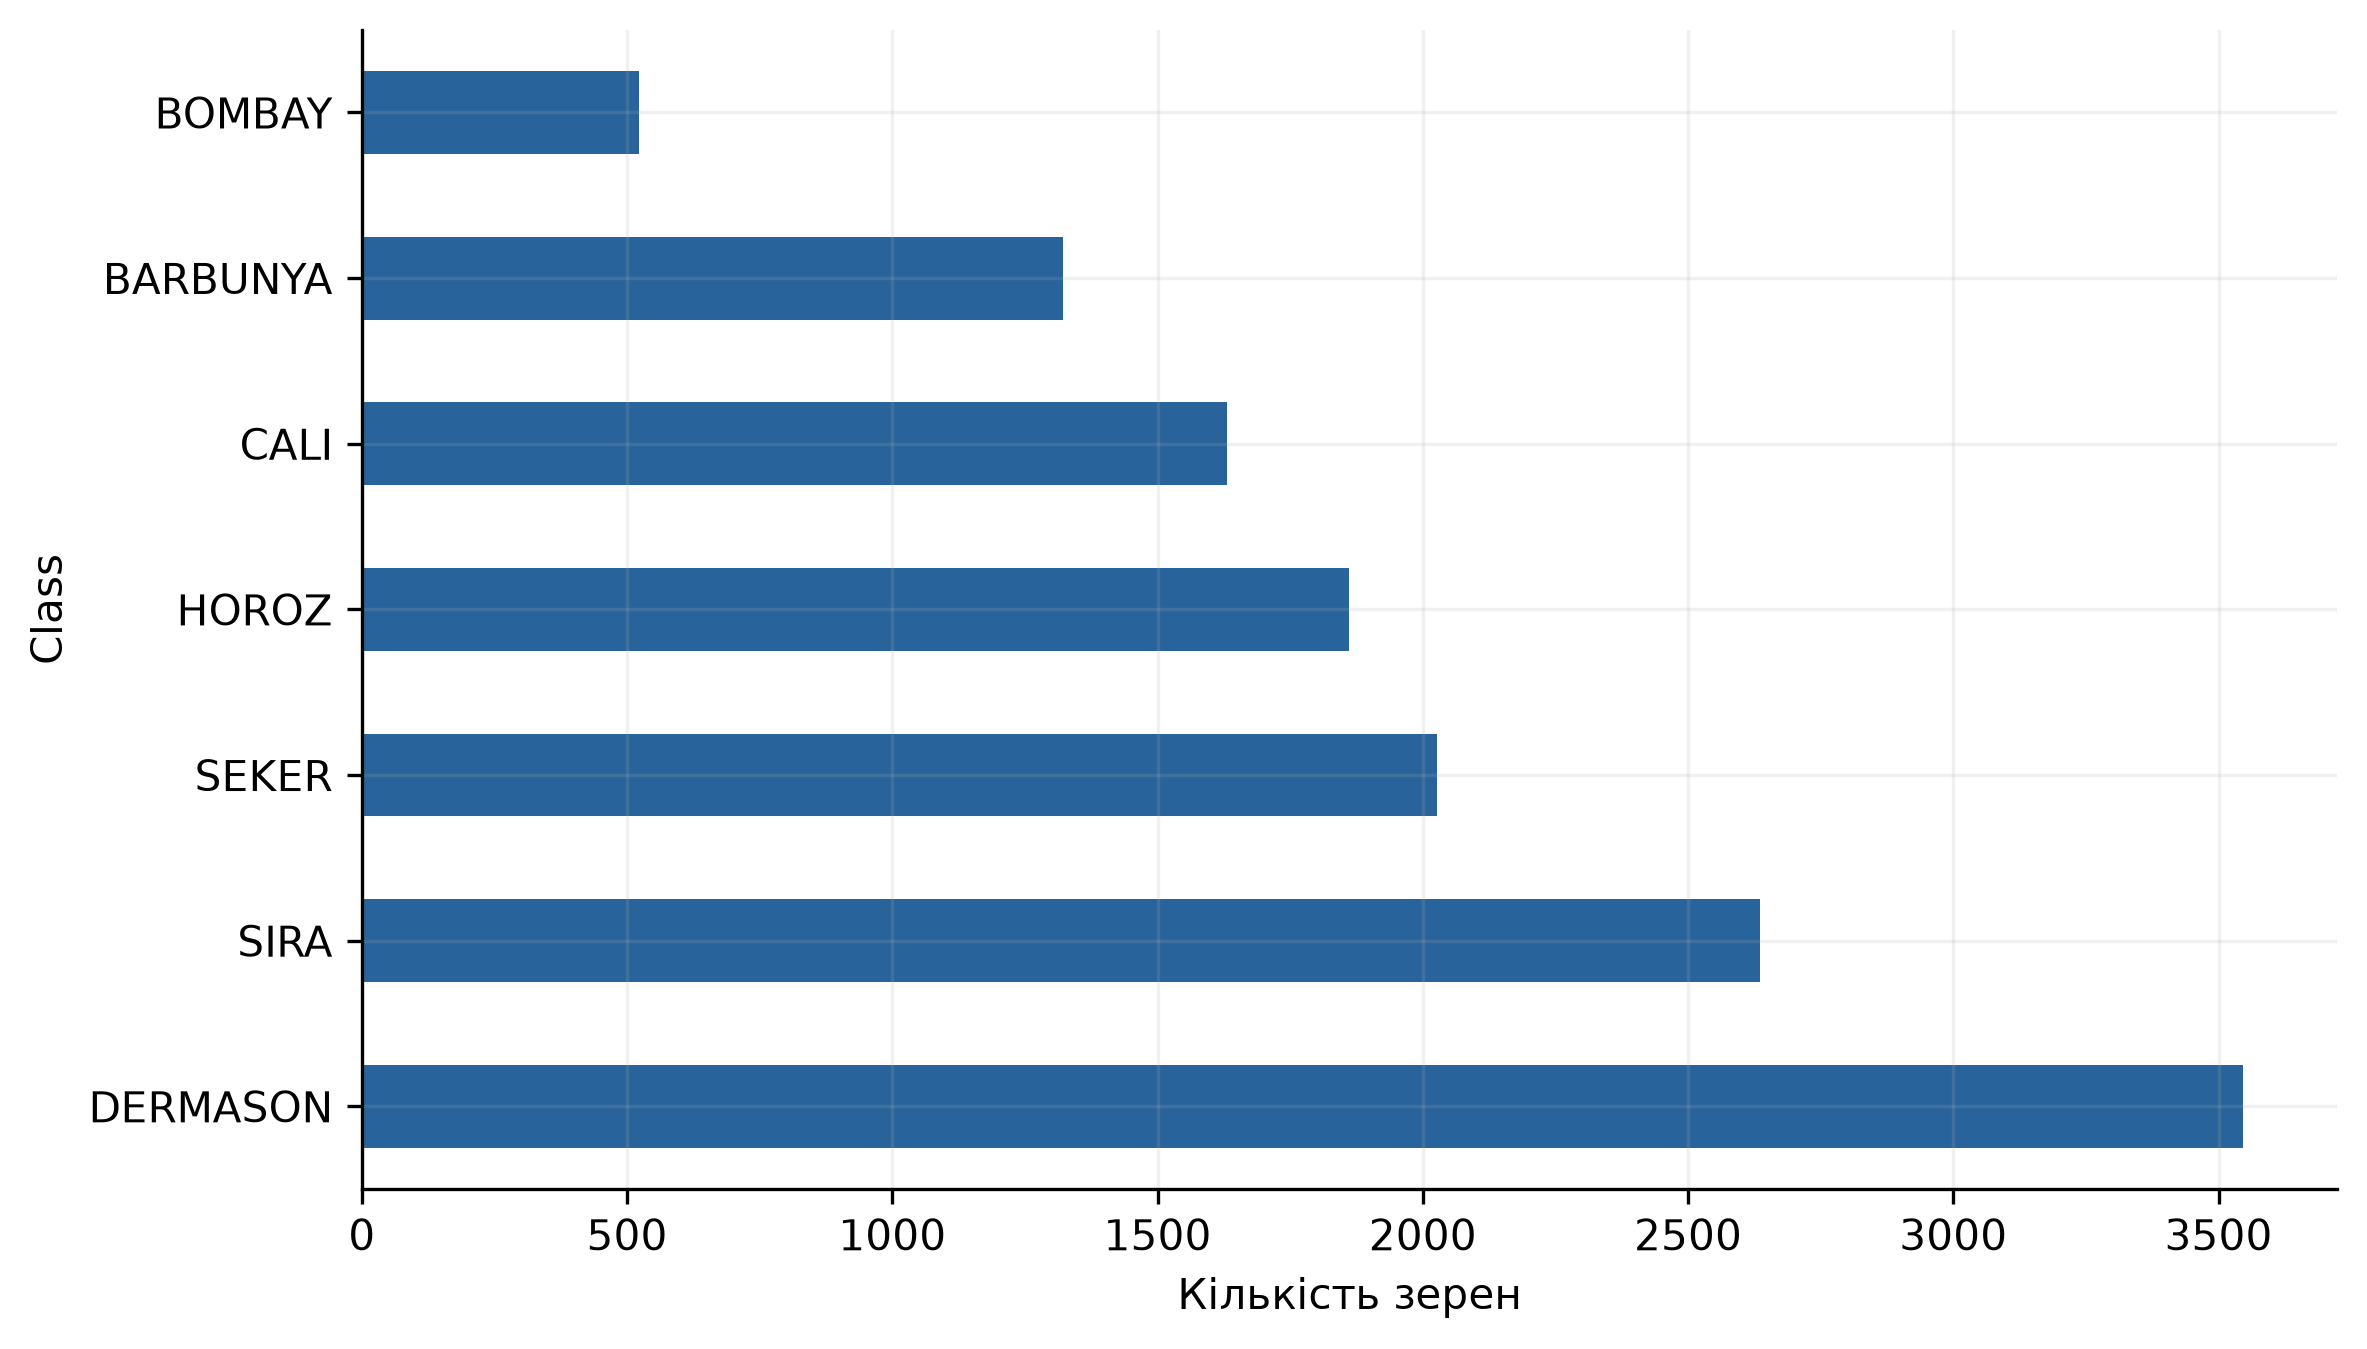

In [20]:
display(Image(filename=str(ROOT / 'lab_02' / 'results' / 'class_balance.png')))

### Рисунок 2. Кореляції числових ознак Dry Bean

На рисунку 2 зображено кореляції числових ознак Dry Bean. Геометричні характеристики зерен взаємозалежні. У моделі збережено всі 16 ознак, а нестійкість ваг обмежується перевіреним на Validation L2-штрафом.

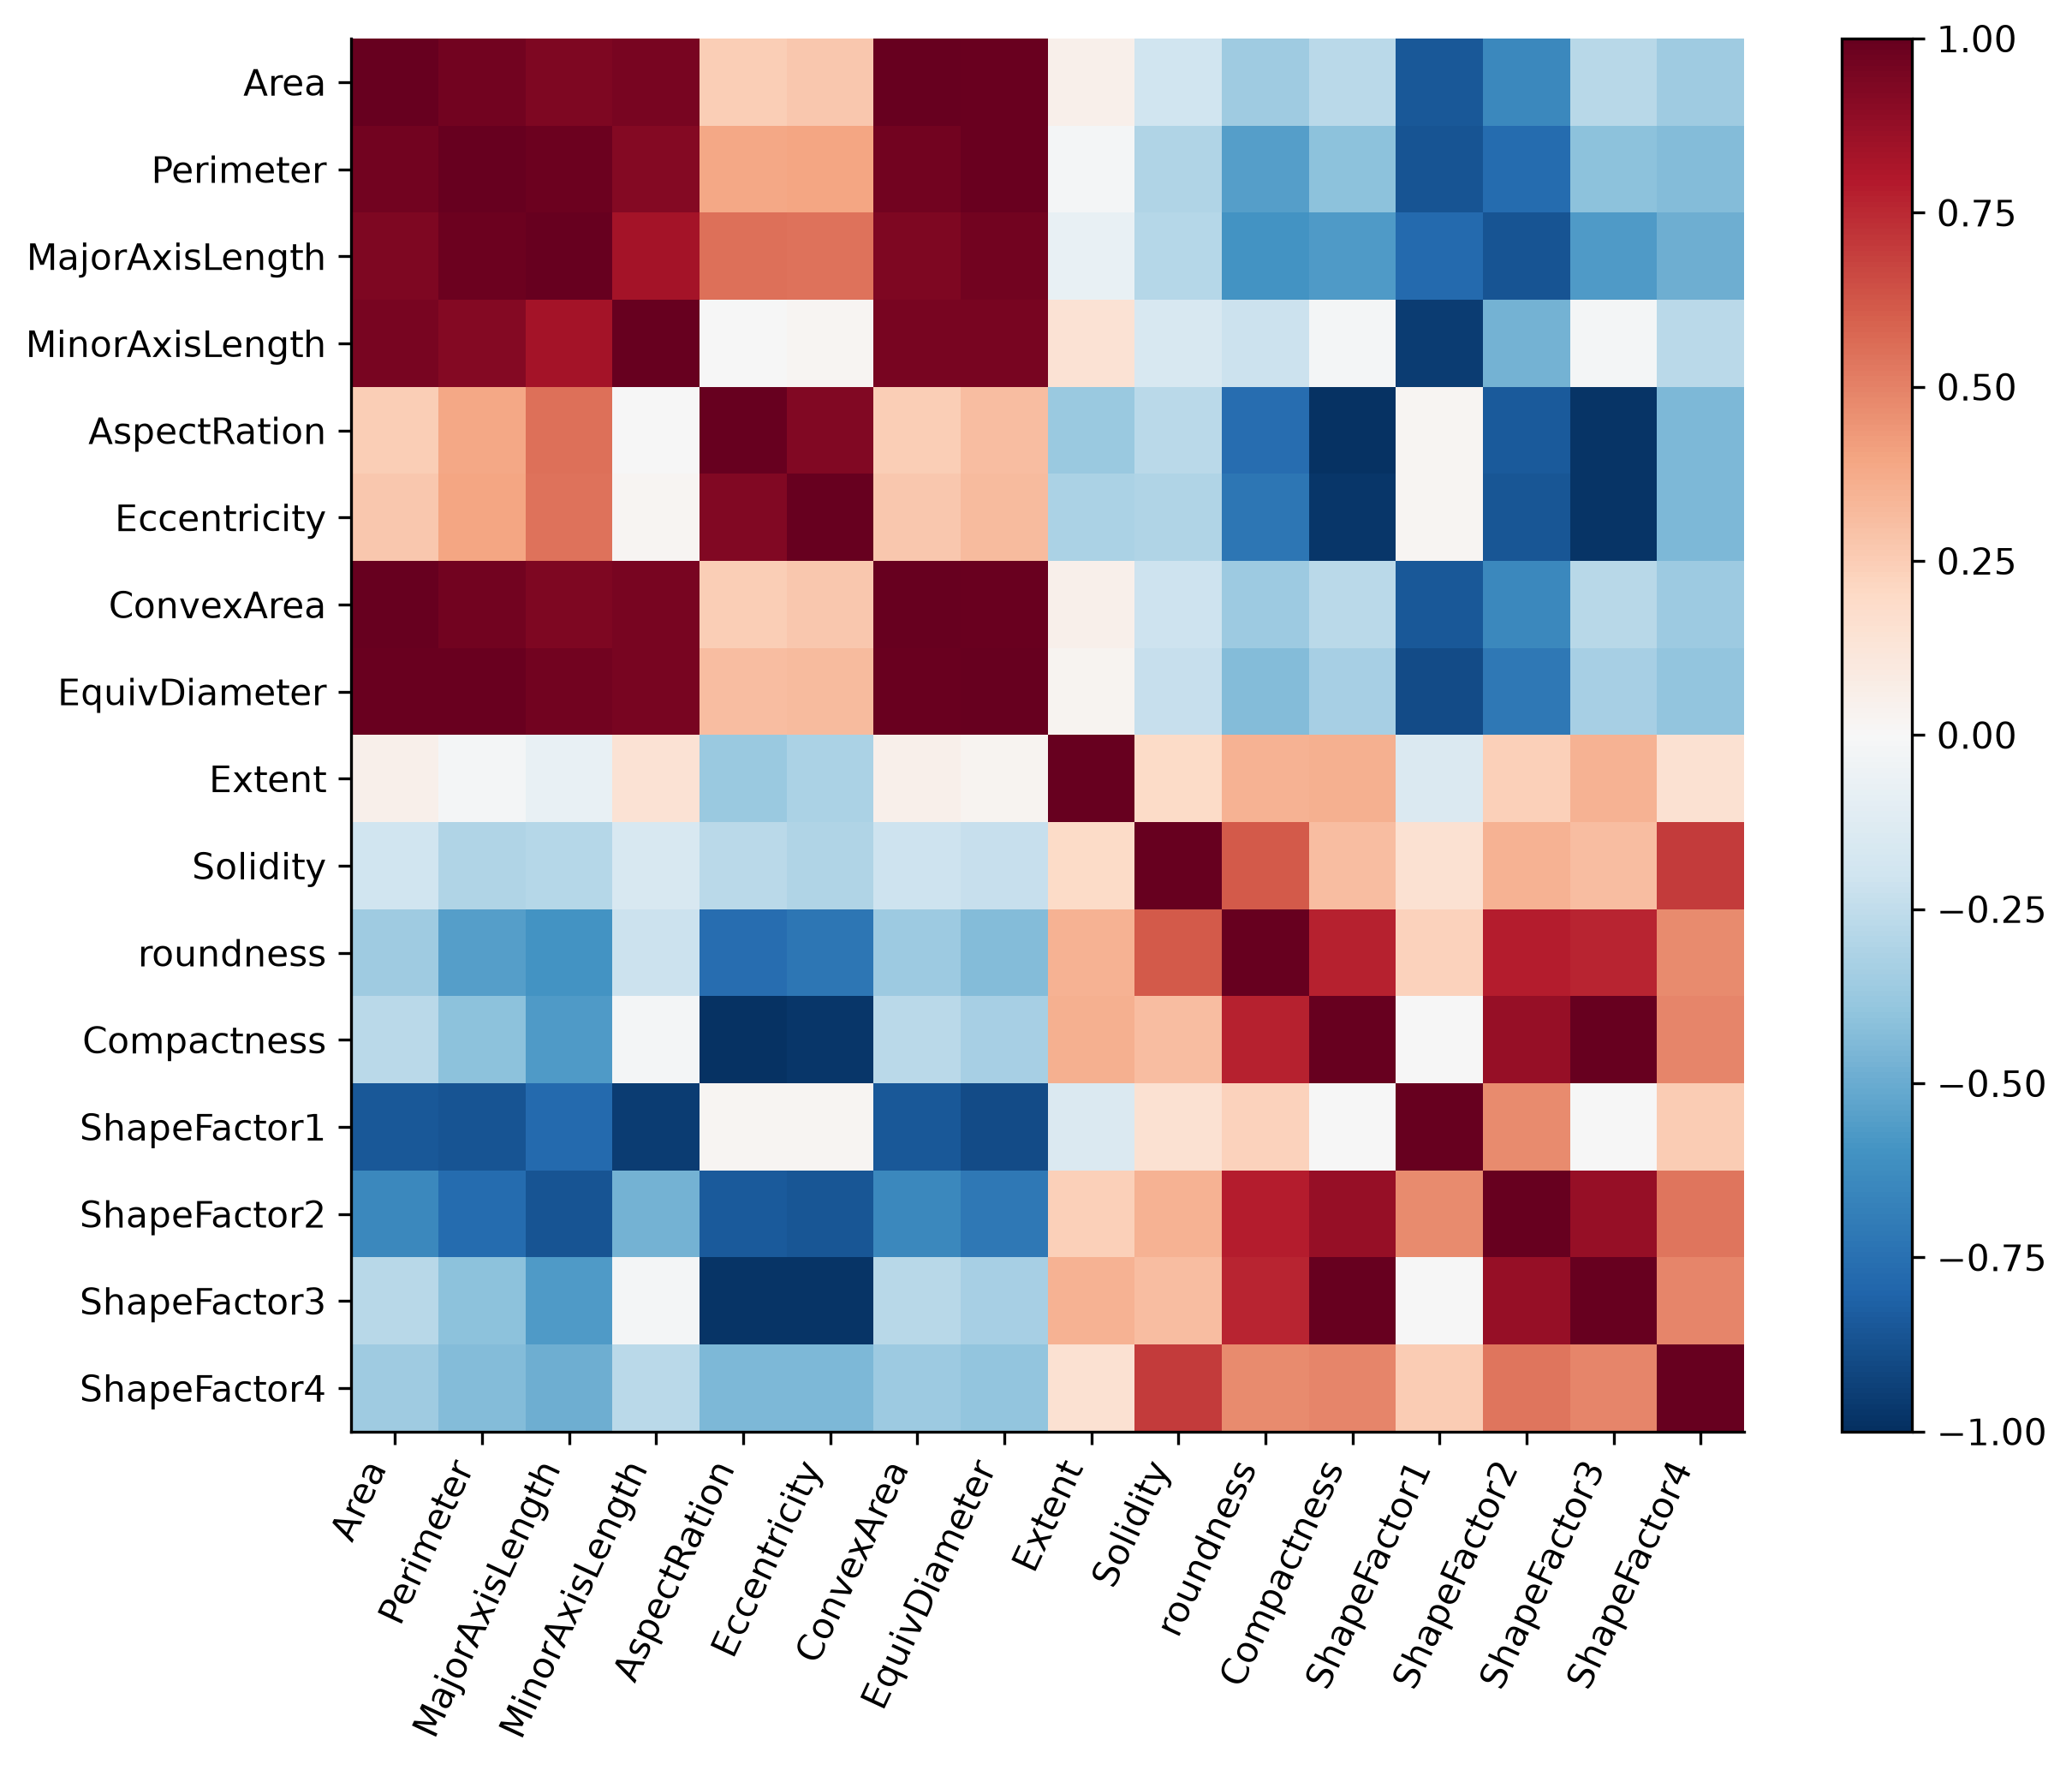

In [21]:
display(Image(filename=str(ROOT / 'lab_02' / 'results' / 'correlations.png')))

### Рисунок 3. Розподіл класів п’яти клієнтів за IID і Dirichlet

На рисунку 3 зображено розподіл класів п’яти клієнтів за IID і Dirichlet. Рядки відповідають клієнтам, стовпці - класам за кодуванням LabelEncoder. Менший α робить локальні дані неодноріднішими.

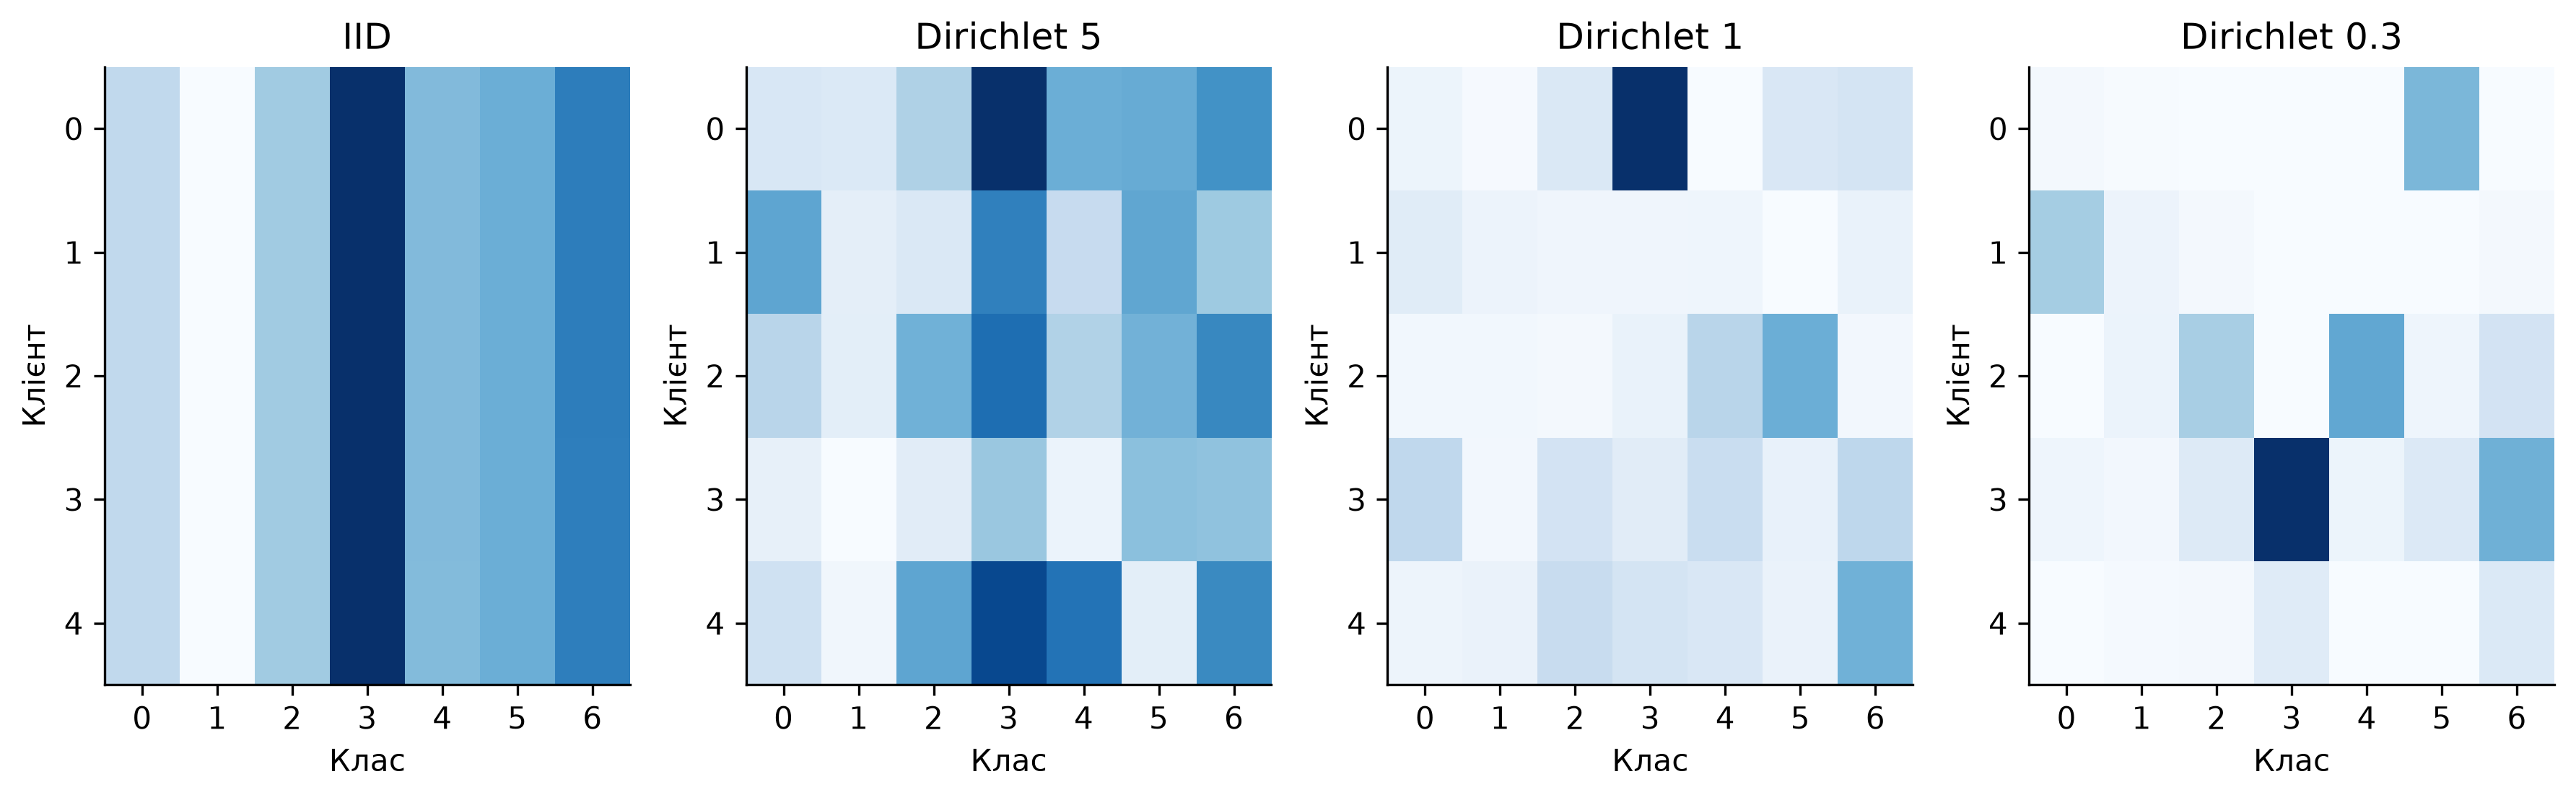

In [22]:
display(Image(filename=str(ROOT / 'lab_02' / 'results' / 'client_class_distribution.png')))

### Рисунок 4. Збіжність централізованої NumPy-моделі

На рисунку 4 зображено збіжність централізованої NumPy-моделі. Train і Validation не змішуються. Для кінцевої оцінки збережено параметри епохи з найменшою Validation loss.

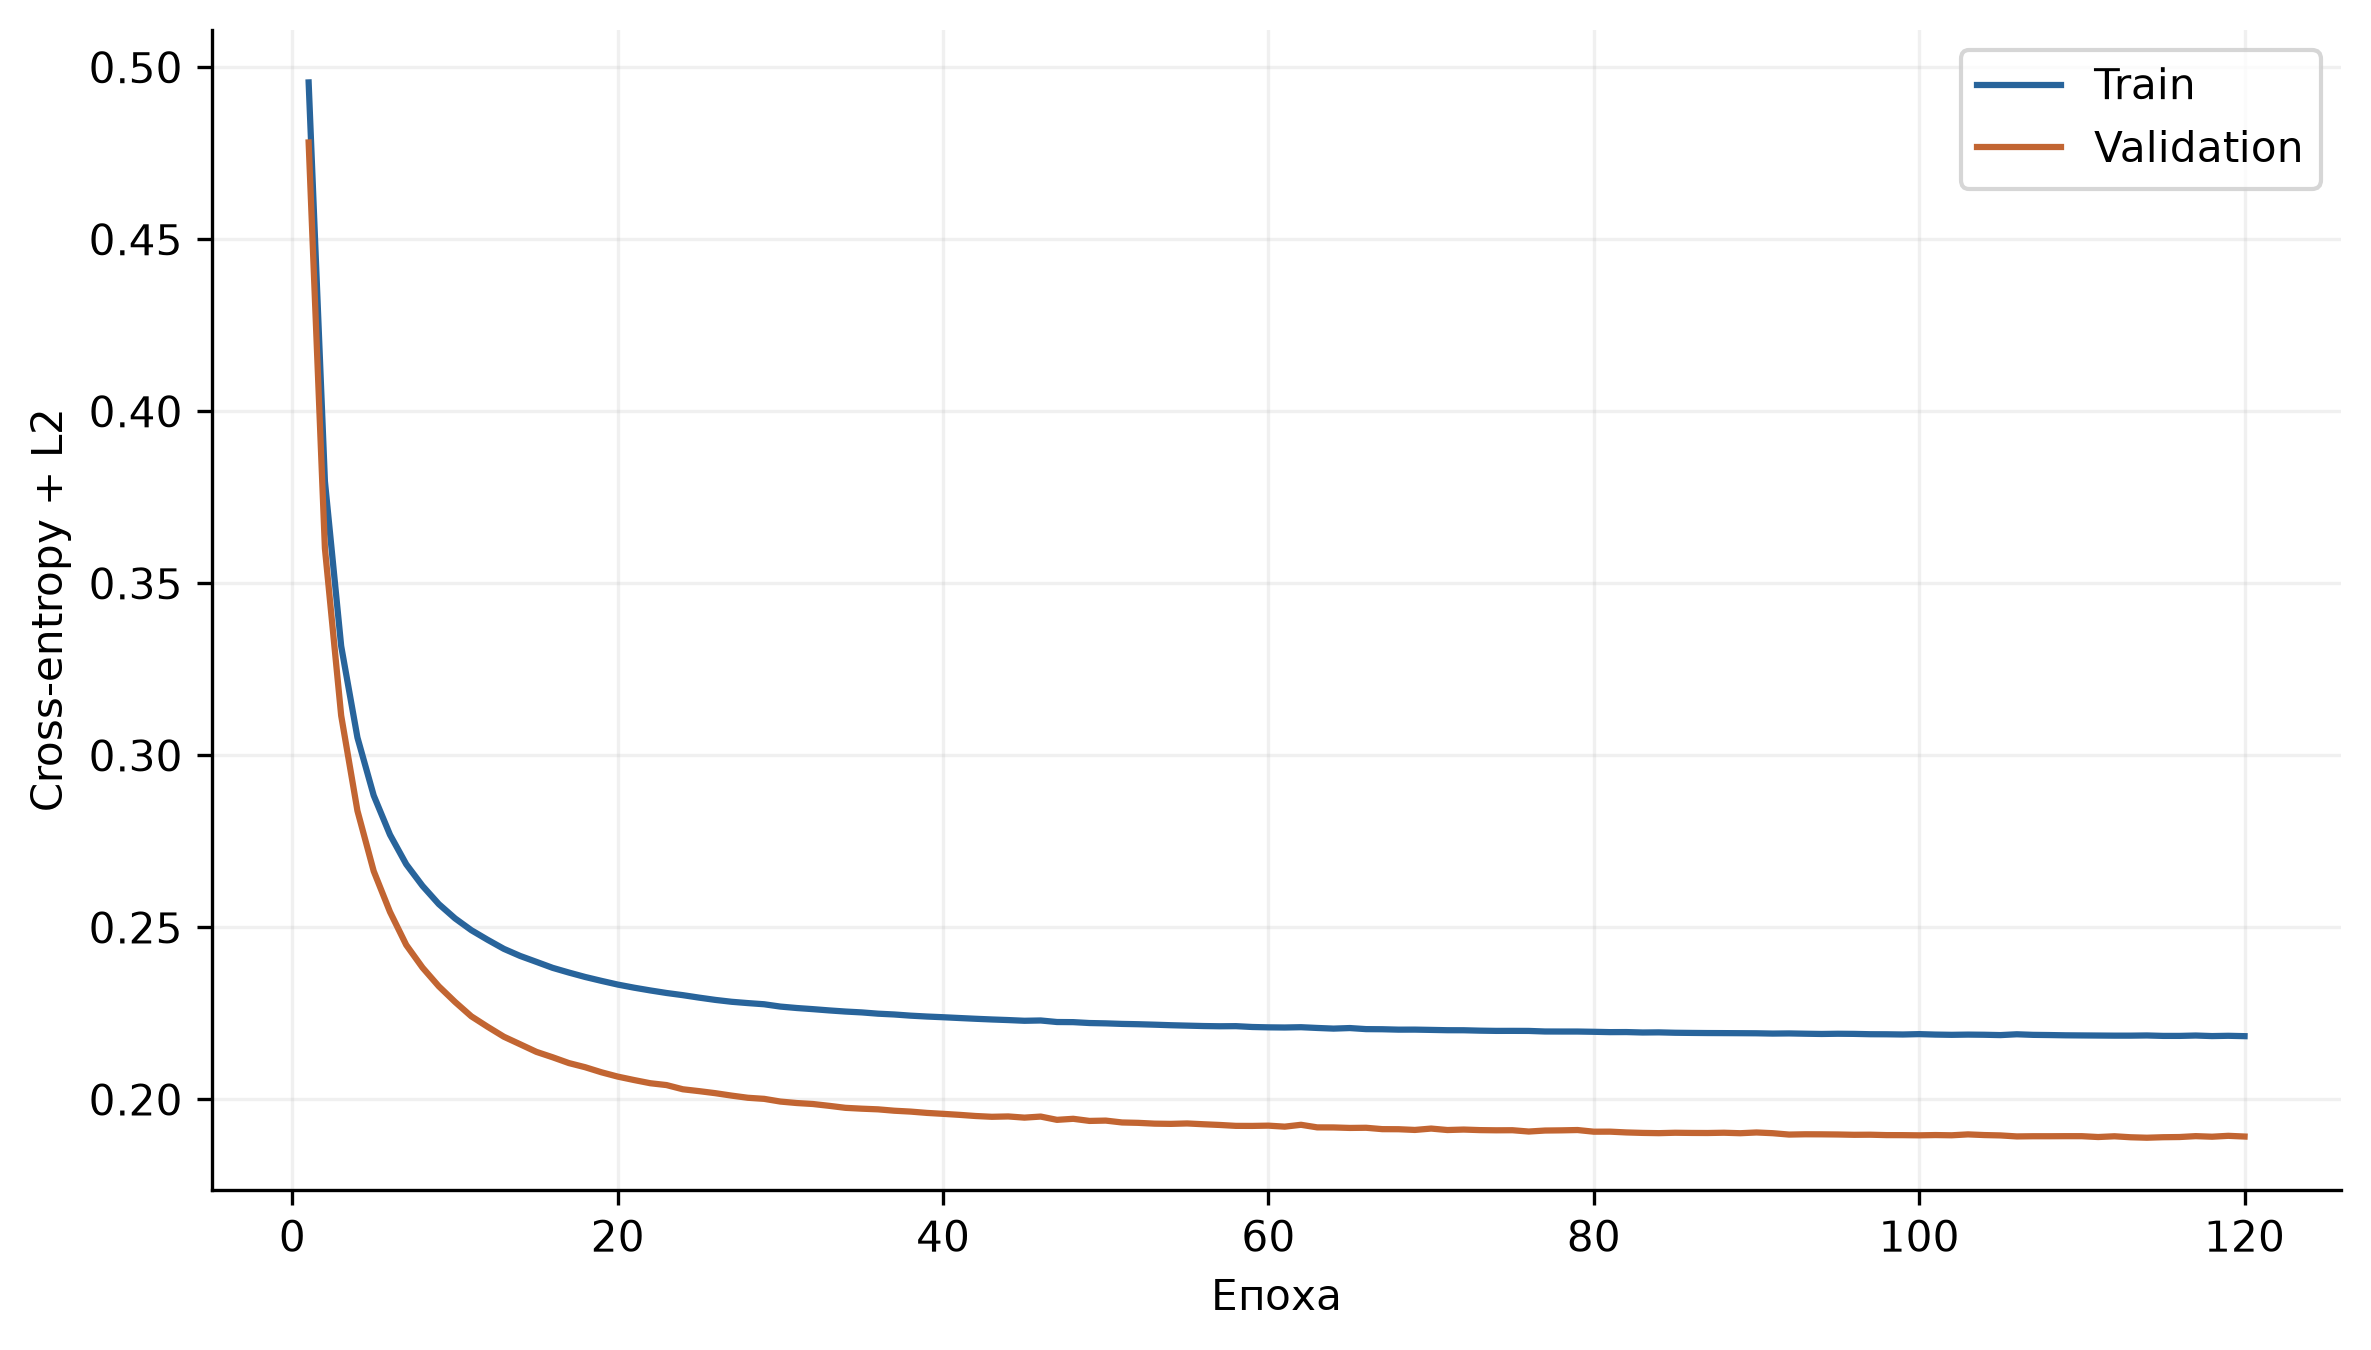

In [23]:
display(Image(filename=str(ROOT / 'lab_02' / 'results' / 'central_learning.png')))

### Рисунок 5. Validation loss глобальних моделей за раундами

На рисунку 5 зображено validation loss глобальних моделей за раундами. Кожна крива відповідає окремому заздалегідь заданому експерименту. Для Test використовується найкращий за Validation раунд цього експерименту.

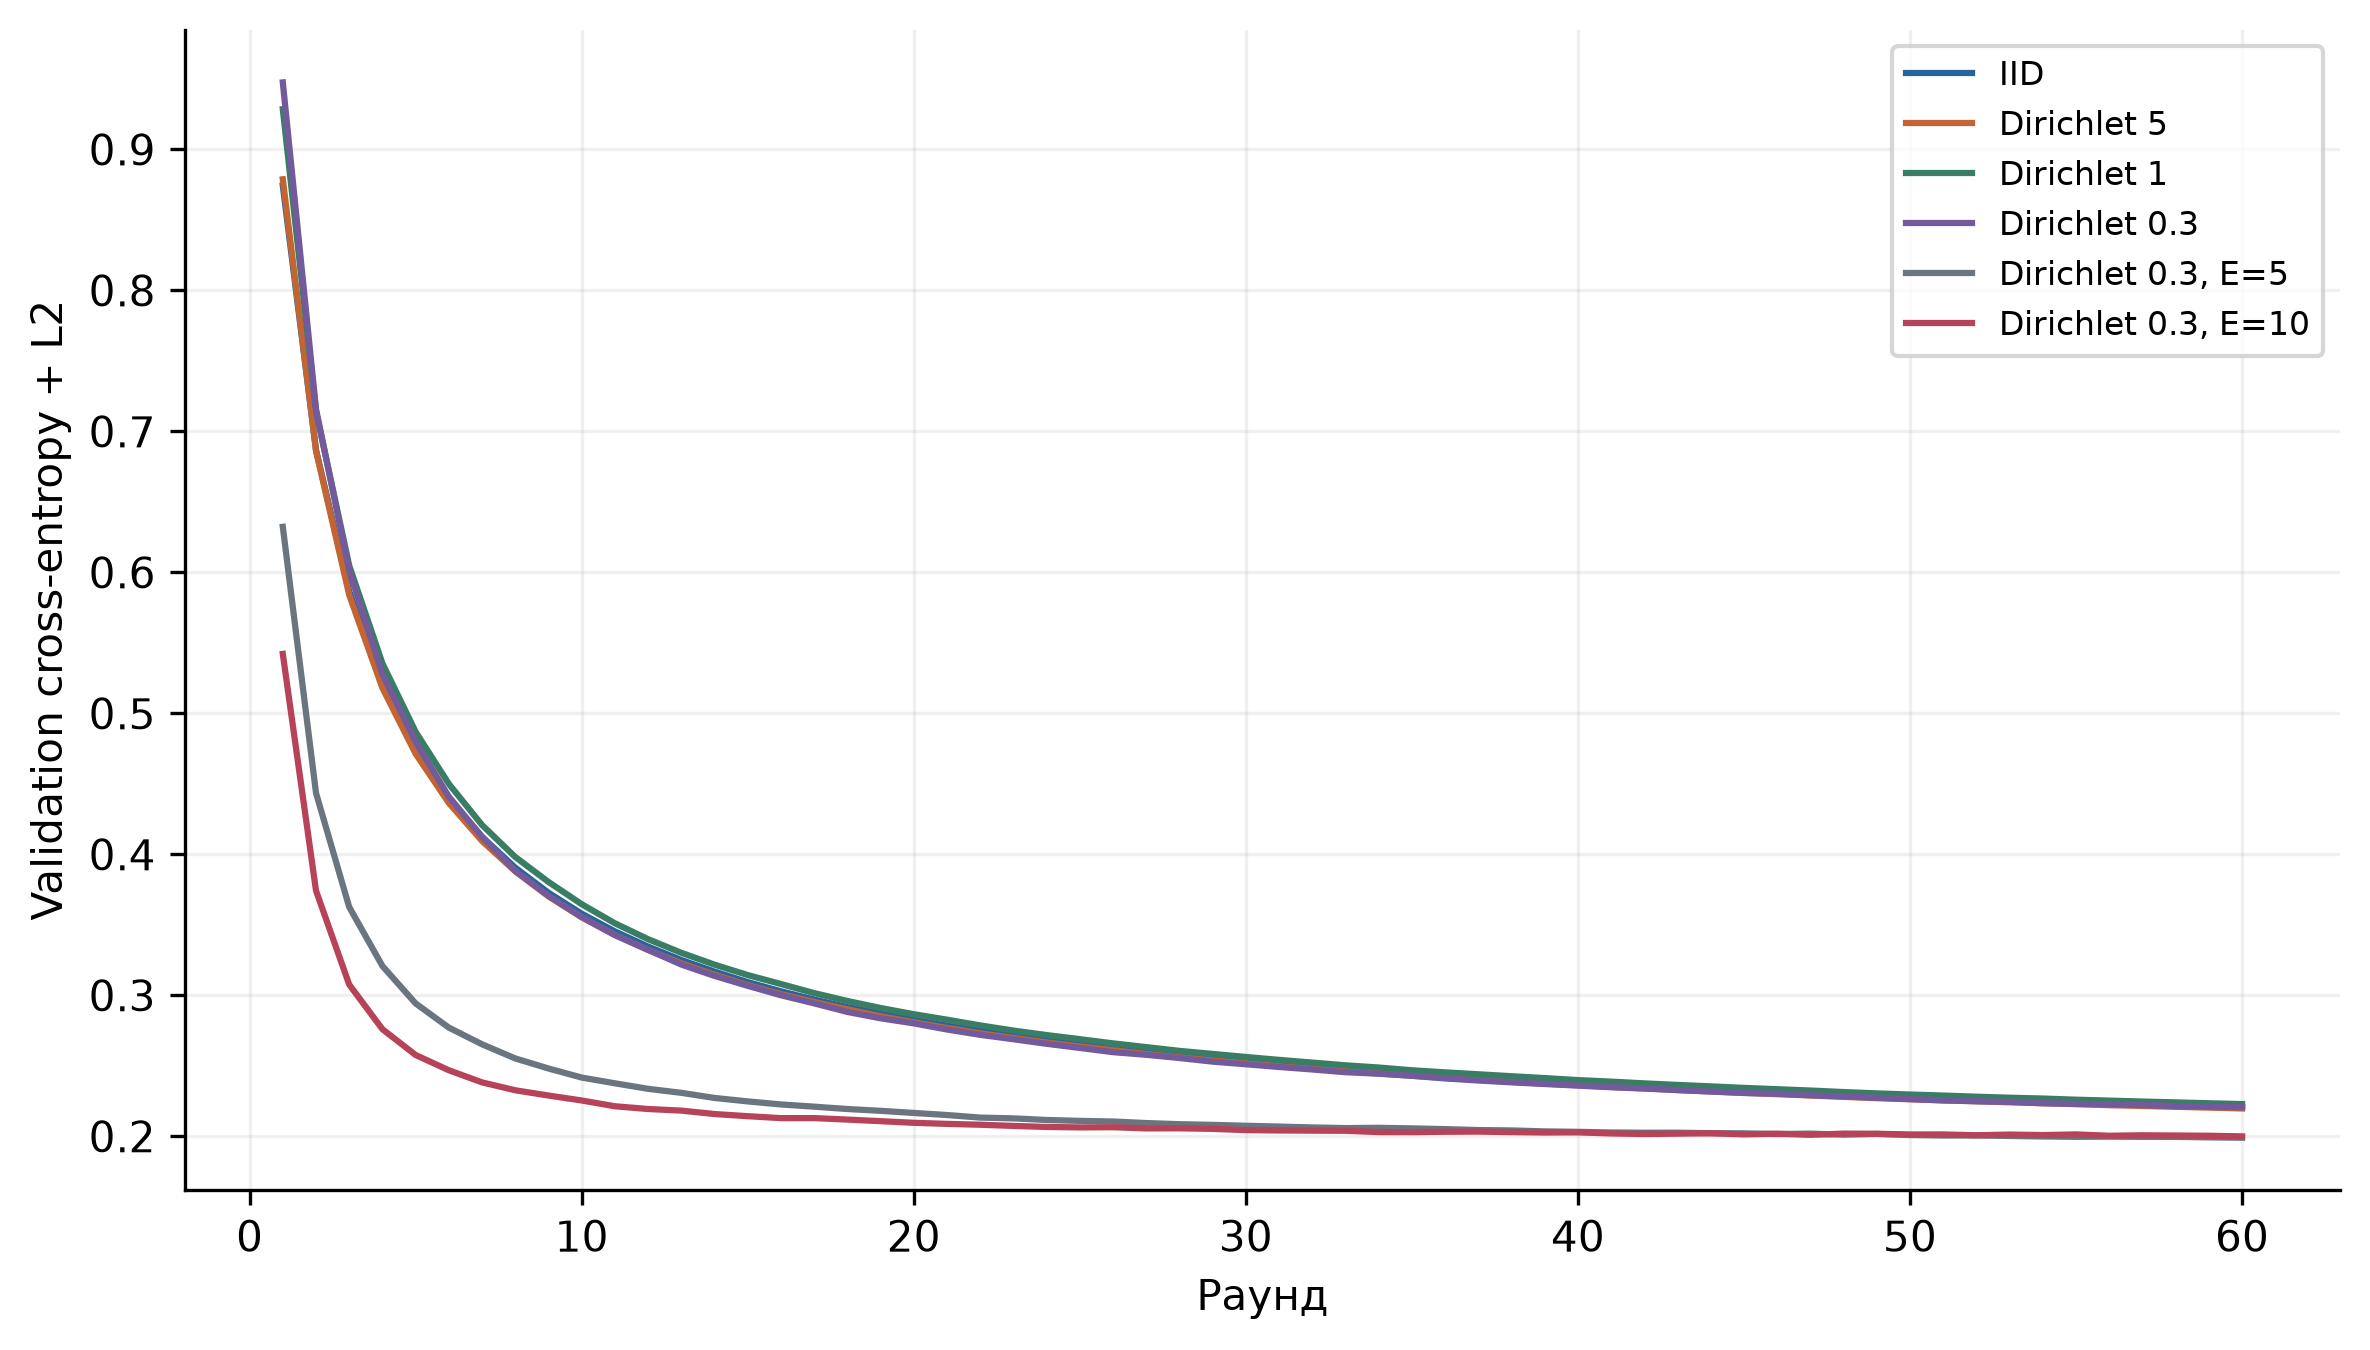

In [24]:
display(Image(filename=str(ROOT / 'lab_02' / 'results' / 'federated_learning.png')))

### Рисунок 6. Вплив α Dirichlet та числа локальних епох

На рисунку 6 зображено вплив α Dirichlet та числа локальних епох. Збільшення E змінює і ступінь локального дрейфу, і кількість обчислень; графік не є порівнянням при однаковому часі роботи.

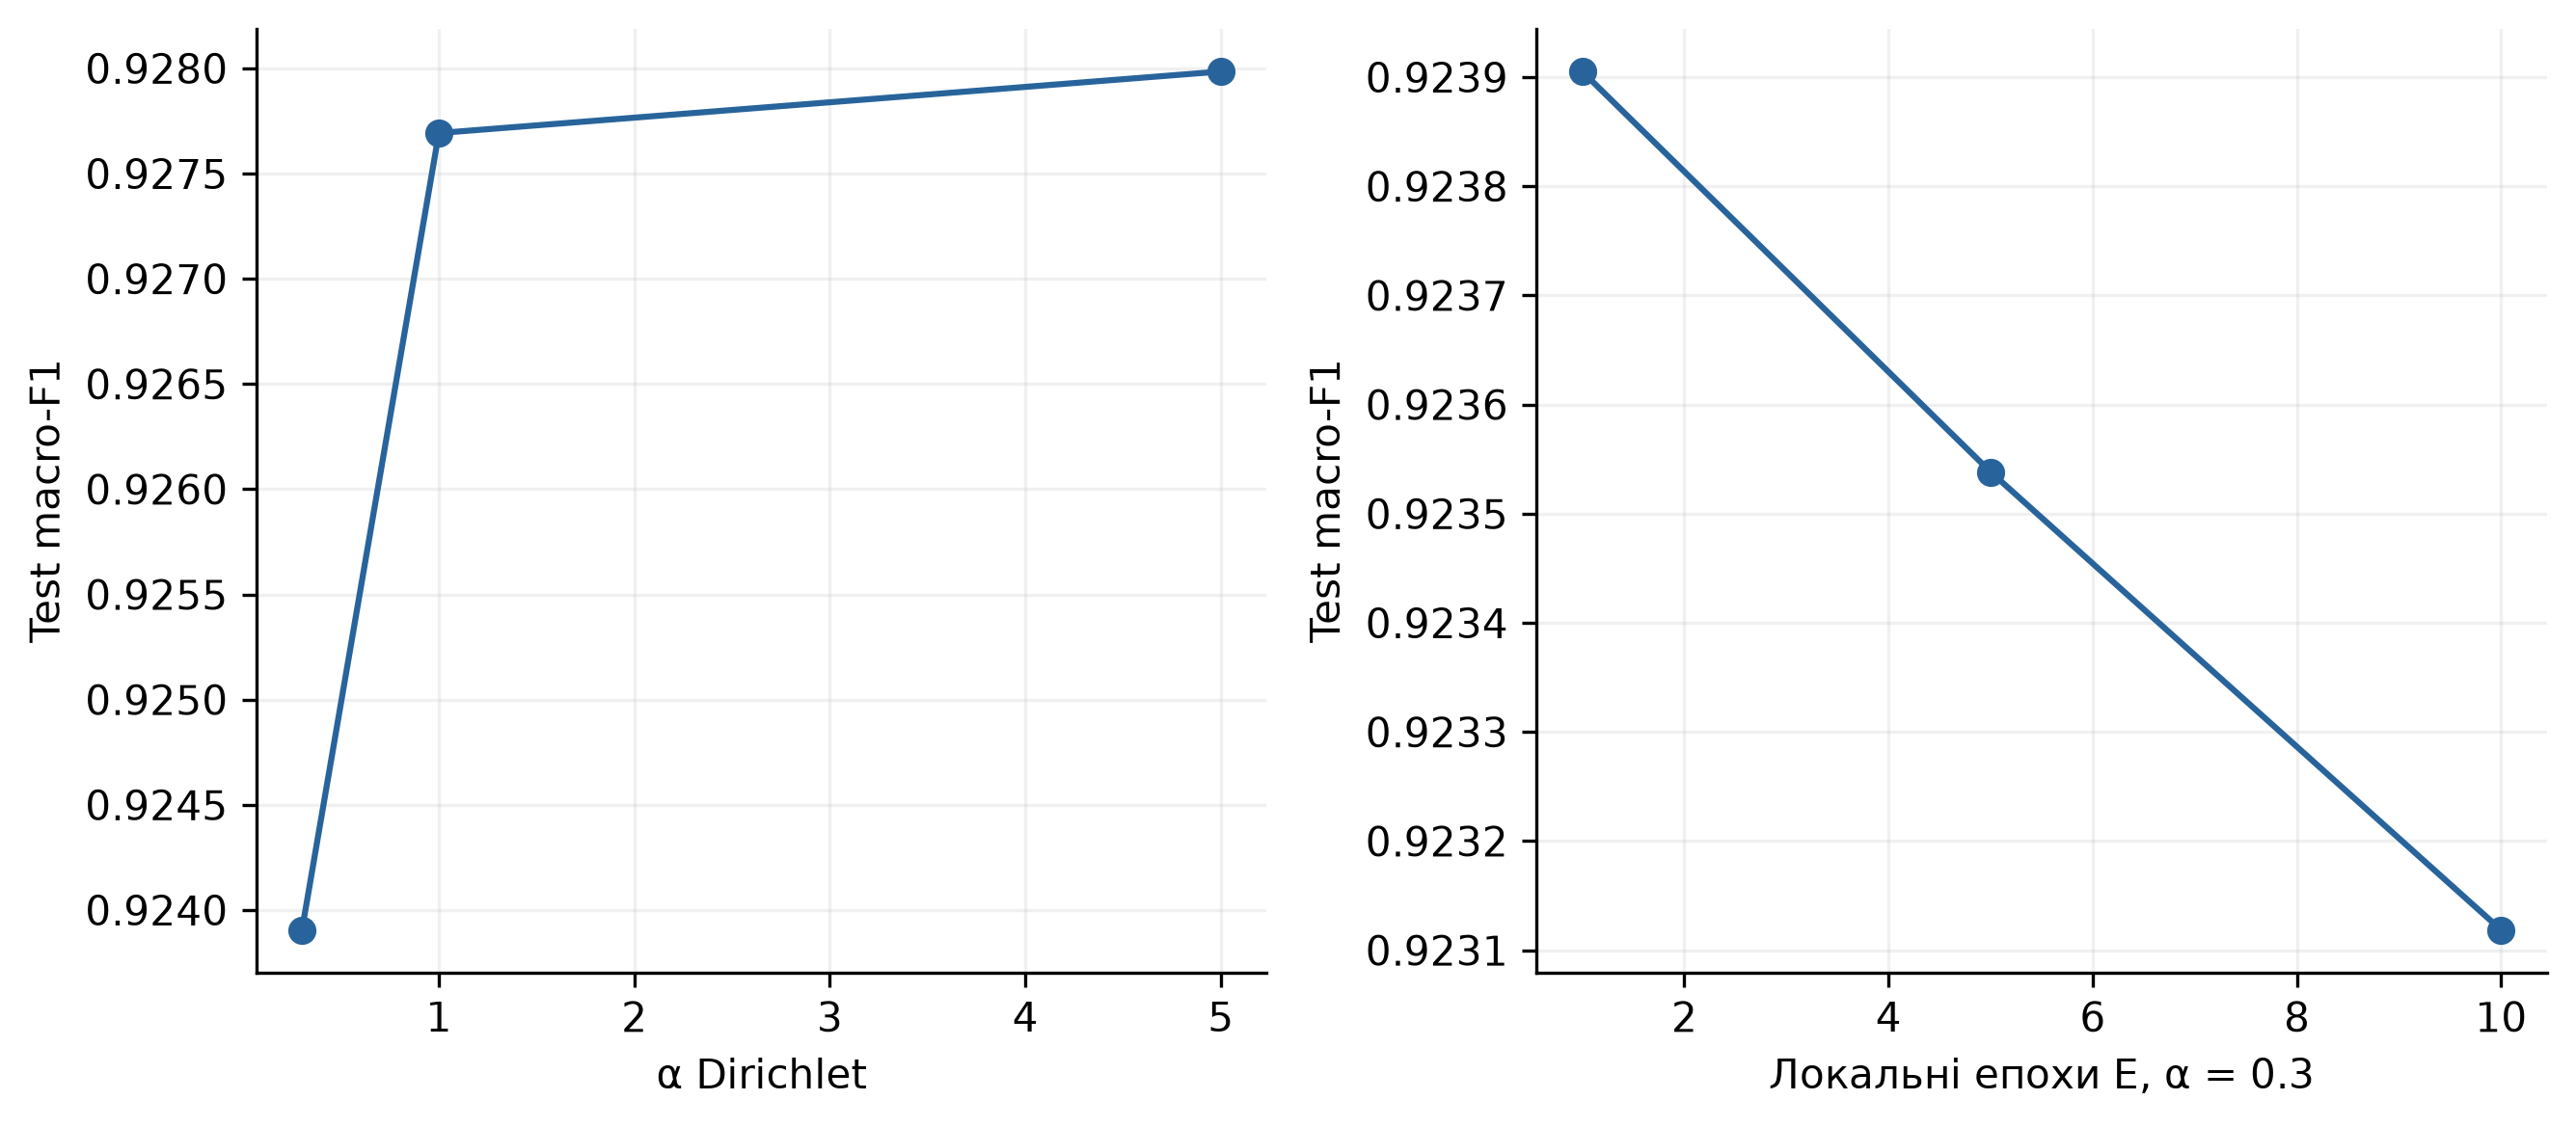

In [25]:
display(Image(filename=str(ROOT / 'lab_02' / 'results' / 'federated_effects.png')))

### Рисунок 7. Матриця плутанини централізованої моделі

На рисунку 7 зображено матриця плутанини централізованої моделі. Діагональ містить правильні класифікації. Поза нею видно, які сорти найважче відокремити за заданими ознаками.

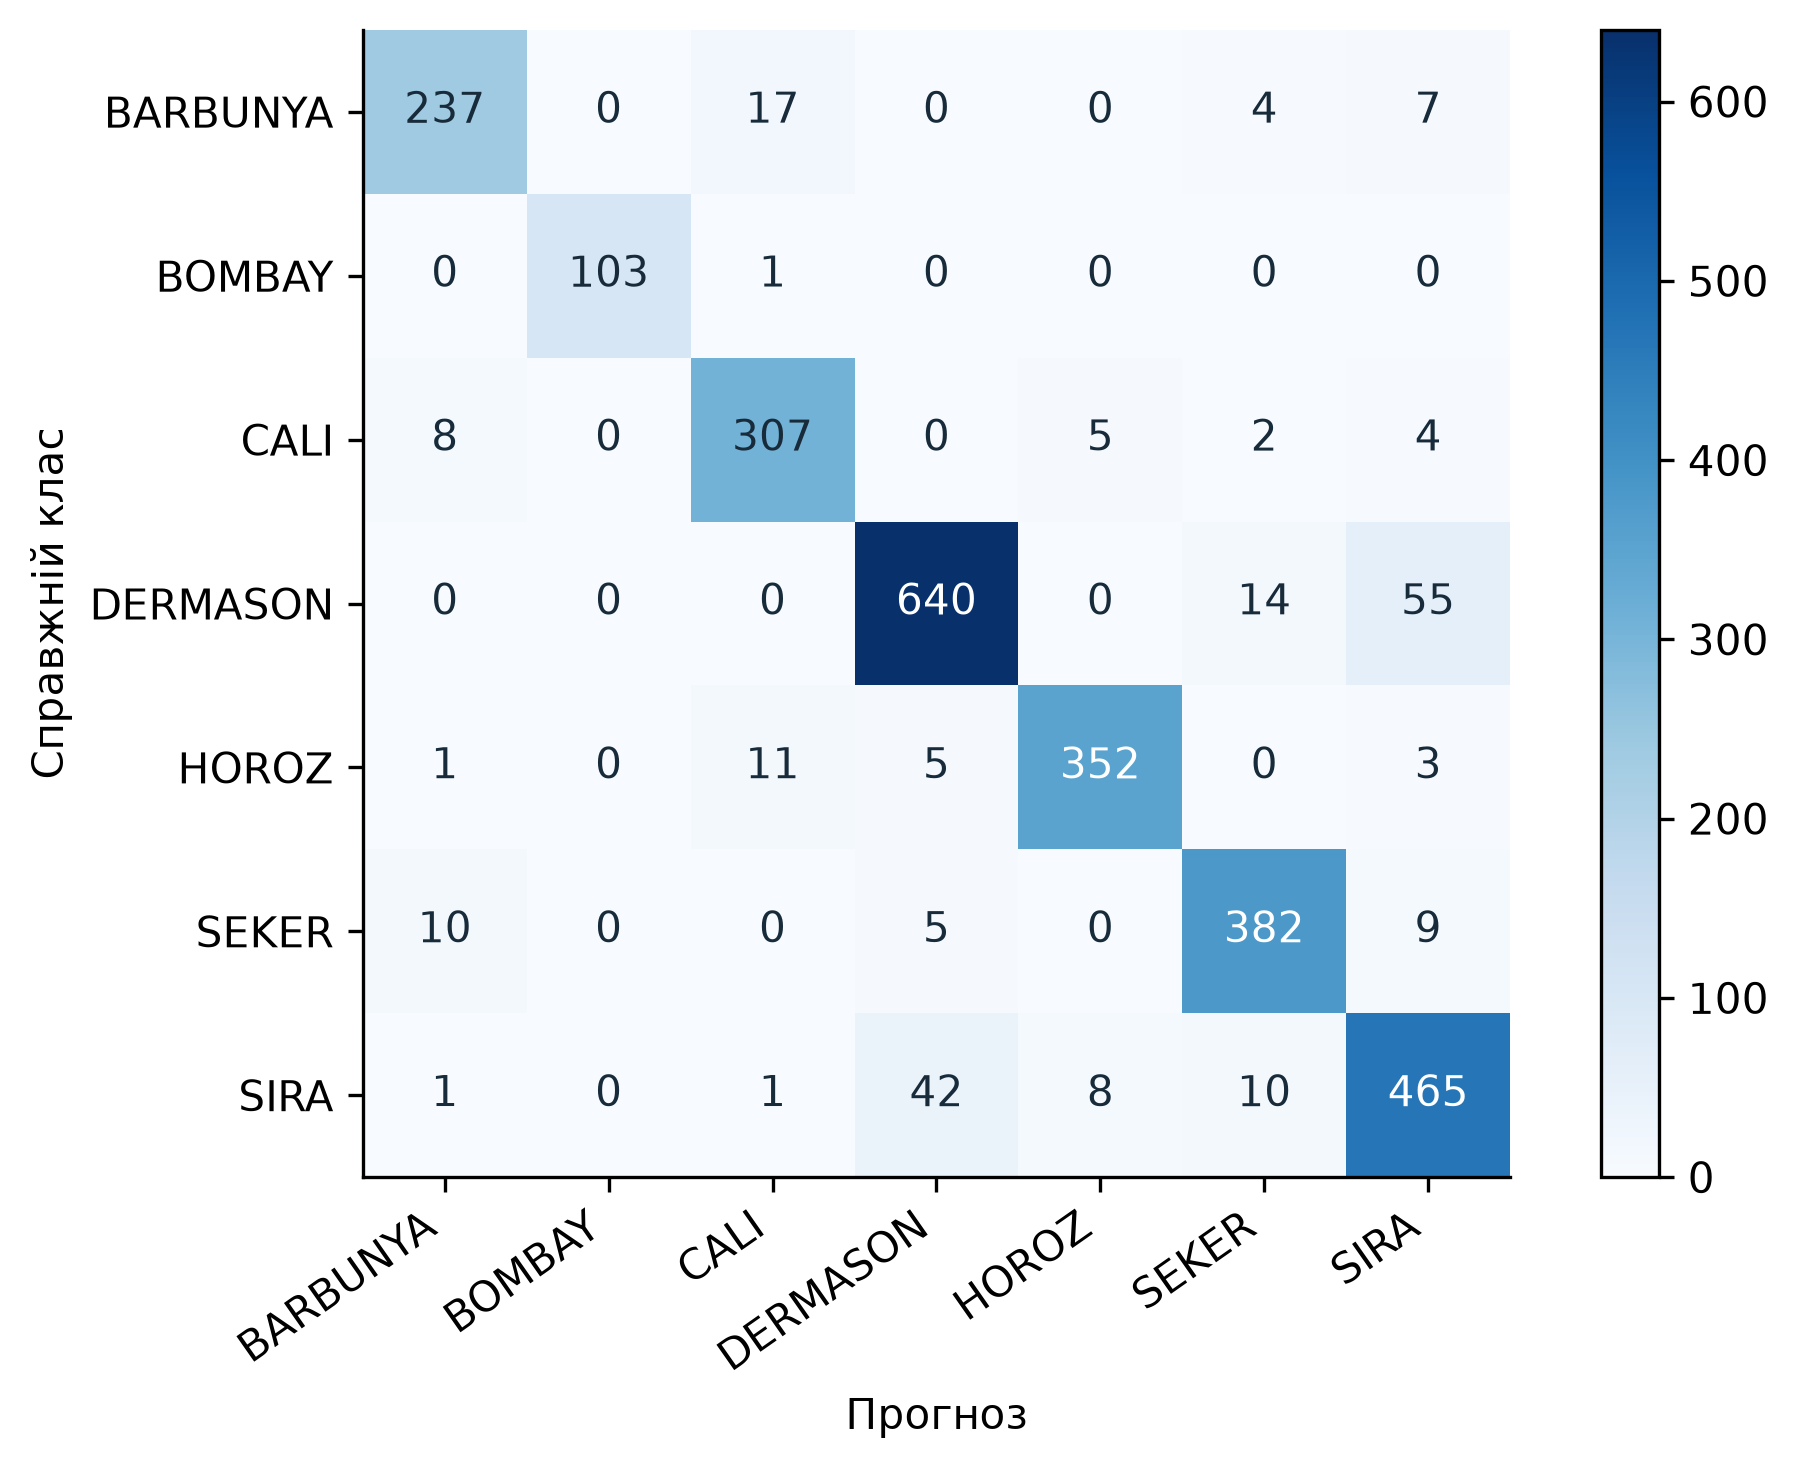

In [26]:
display(Image(filename=str(ROOT / 'lab_02' / 'results' / 'confusion_central.png')))

## Висновки

In [27]:
for text in conclusions(2, R):
    print(text)

Централізована модель отримала Test macro-F1=0,9288. Для IID FedAvg значення становить 0,9278, а для Dirichlet α=0,3 і E=1 - 0,9239.
За α=0,3 зміна E з 1 до 10 дала macro-F1=0,9231. Висновок обмежений однією відтворюваною реалізацією розподілу й однаковими 60 раундами, а не рівними витратами обчислень. FedAvg, softmax та градієнти реалізовано NumPy; сирі дані клієнтів у серверному класі не зберігаються.


## Джерела

Koklu M., Ozkan I. Dry Bean. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/602/dry+bean+dataset